Signal:
Selected MC events: 35664 / 100000
ZZ background:
Selected MC events: 35294 / 100000

Expected signal events:     0.0969317
Expected background events: 258778


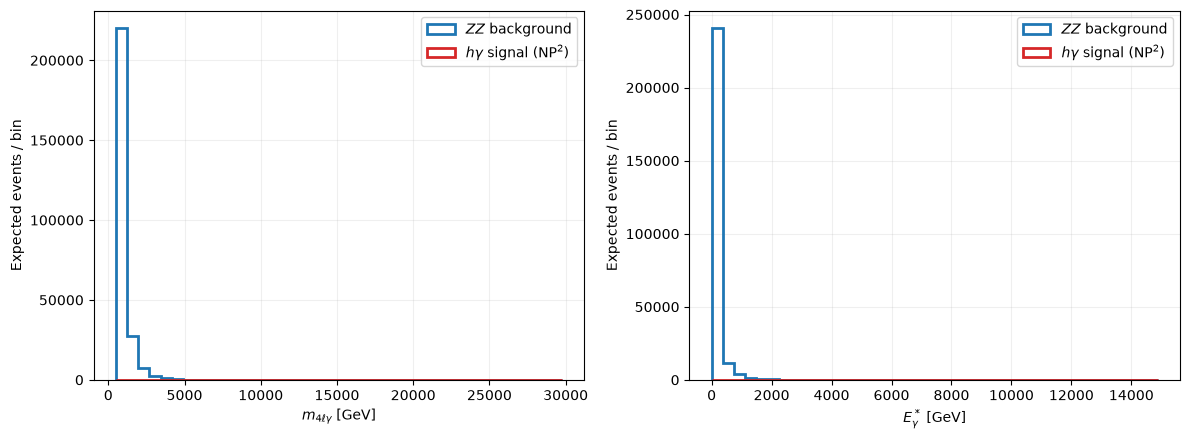

In [ ]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt

# ---------- Inputs ----------

signal_file = "/Volumes/Keshav_NVMeM2/FCC-hh-runs/pp_to_ha/signal/NP2/Events/run_01/tag_1_delphes_events.root"
background_file = "/Volumes/Keshav_NVMeM2/FCC-hh-runs/pp_to_ha/bckg/pp_to_zz/Events/run_01/tag_1_delphes_events.root"

sigma_signal_pb = 1.355562e-14       # MG cross section for pp > h a, h > 4l
sigma_background_pb = 0.036696   # MG cross section for pp > z z, z > l+ l-

luminosity_pb = 2e7          # 20 ab^-1
mass_cut = 500.0             # GeV

# Leave at 1 to plot the signal at its generation point.
# Otherwise: [(c / Lambda**2) / (c_generated / Lambda_generated**2)]**2
signal_scale = 1000000.0


# ---------- Four-momentum: [E, px, py, pz] ----------

def four_vector(pt, eta, phi):
    # Neglect electron and muon masses.
    return np.array([
        pt * np.cosh(eta),
        pt * np.cos(phi),
        pt * np.sin(phi),
        pt * np.sinh(eta),
    ])


def invariant_mass(p):
    return np.sqrt(max(p[0]**2 - np.dot(p[1:], p[1:]), 0.0))


# ---------- Read events and apply selection ----------

def read_sample(filename, sigma_pb):
    branches = [
        f"{obj}.{quantity}"
        for obj in ("Electron", "Muon", "Photon")
        for quantity in ("PT", "Eta", "Phi")
    ]

    with uproot.open(filename) as f:
        tree = f["Delphes"]
        data = tree.arrays(branches, library="ak", how=dict)
        n_events = tree.num_entries

        if "Event.Weight" in tree:
            weights = ak.to_numpy(
                ak.flatten(tree["Event.Weight"].array(library="ak"))
            )
        else:
            weights = np.ones(n_events)

    # Normalize BEFORE applying analysis cuts.
    event_weights = weights * sigma_pb * luminosity_pb / weights.sum()

    masses, photon_energies, selected_weights = [], [], []

    for i in range(n_events):
        n_leptons = (
            len(data["Electron.PT"][i]) + len(data["Muon.PT"][i])
        )

        if n_leptons != 4 or len(data["Photon.PT"][i]) == 0:
            continue

        # Sum the four reconstructed lepton momenta.
        p4l = np.zeros(4)

        for obj in ("Electron", "Muon"):
            for pt, eta, phi in zip(
                data[f"{obj}.PT"][i],
                data[f"{obj}.Eta"][i],
                data[f"{obj}.Phi"][i],
            ):
                p4l += four_vector(float(pt), float(eta), float(phi))

        # Choose the highest-pT reconstructed photon.
        j = int(ak.argmax(data["Photon.PT"][i]))

        photon = four_vector(
            float(data["Photon.PT"][i][j]),
            float(data["Photon.Eta"][i][j]),
            float(data["Photon.Phi"][i][j]),
        )

        total = p4l + photon
        mass = invariant_mass(total)

        if mass <= mass_cut:
            continue

        # Photon energy in the reconstructed 4l + photon rest frame.
        energy_star = (
            total[0] * photon[0] - np.dot(total[1:], photon[1:])
        ) / mass

        masses.append(mass)
        photon_energies.append(energy_star)
        selected_weights.append(event_weights[i])

    print(f"Selected MC events: {len(masses)} / {n_events}")

    return {
        "mass": np.asarray(masses),
        "energy": np.asarray(photon_energies),
        "weights": np.asarray(selected_weights),
    }


# ---------- Process the two samples ----------

if sigma_signal_pb is None or sigma_background_pb is None:
    raise ValueError("Enter the two MadGraph cross sections in pb above.")

print("Signal:")
signal = read_sample(signal_file, sigma_signal_pb)

print("ZZ background:")
background = read_sample(background_file, sigma_background_pb)

signal["weights"] *= signal_scale

print(f"\nExpected signal events:     {signal['weights'].sum():.6g}")
print(f"Expected background events: {background['weights'].sum():.6g}")


# ---------- Histograms ----------

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, variable, xlabel in zip(
    axes,
    ("mass", "energy"),
    (r"$m_{4\ell\gamma}$ [GeV]", r"$E_\gamma^*$ [GeV]"),
):
    values = np.concatenate([signal[variable], background[variable]])
    lower = mass_cut if variable == "mass" else 0.0
    upper = max(values.max() if values.size else lower + 100, lower + 100)
    bins = np.linspace(lower, upper, 41)

    for sample, label, color in (
        (background, r"$ZZ$ background", "tab:blue"),
        (signal, r"$h\gamma$ signal (NP$^2$)", "tab:red"),
    ):
        ax.hist(
            sample[variable],
            bins=bins,
            weights=sample["weights"],
            histtype="step",
            linewidth=2,
            label=label,
            color=color,
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel("Expected events / bin")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
def check_cutflow(filename):
    branches = [
        f"{obj}.{quantity}"
        for obj in ("Electron", "Muon", "Photon")
        for quantity in ("PT", "Eta", "Phi")
    ]

    with uproot.open(filename) as f:
        data = f["Delphes"].arrays(branches, library="ak", how=dict)

    n_leptons = (
        ak.num(data["Electron.PT"]) + ak.num(data["Muon.PT"])
    )
    n_photons = ak.num(data["Photon.PT"])

    four_leptons = ak.to_numpy(n_leptons == 4)
    has_photon = ak.to_numpy(n_photons >= 1)
    candidates = four_leptons & has_photon

    passed_mass = 0

    for i in np.flatnonzero(candidates):
        p4l = np.zeros(4)

        for obj in ("Electron", "Muon"):
            for pt, eta, phi in zip(
                data[f"{obj}.PT"][i],
                data[f"{obj}.Eta"][i],
                data[f"{obj}.Phi"][i],
            ):
                p4l += four_vector(float(pt), float(eta), float(phi))

        j = int(ak.argmax(data["Photon.PT"][i]))
        photon = four_vector(
            float(data["Photon.PT"][i][j]),
            float(data["Photon.Eta"][i][j]),
            float(data["Photon.Phi"][i][j]),
        )

        if invariant_mass(p4l + photon) > mass_cut:
            passed_mass += 1

    counts = [
        ("All events", len(n_leptons)),
        ("Exactly 4 leptons", int(four_leptons.sum())),
        ("+ at least 1 photon", int(candidates.sum())),
        (f"+ mass > {mass_cut:g} GeV", passed_mass),
    ]

    previous = counts[0][1]
    for label, count in counts:
        efficiency = 100 * count / previous if previous else 0
        print(f"{label:25s}: {count:7d}  ({efficiency:5.1f}% of previous)")
        previous = count

    print("\nReconstructed lepton multiplicities:")
    numbers, counts = np.unique(ak.to_numpy(n_leptons), return_counts=True)
    for number, count in zip(numbers, counts):
        print(f"  {number} leptons: {count}")


print("SIGNAL")
check_cutflow(signal_file)

print("\nZZ BACKGROUND")
check_cutflow(background_file)

SIGNAL
All events               :  100000  (100.0% of previous)
Exactly 4 leptons        :   40263  ( 40.3% of previous)
+ at least 1 photon      :   39605  ( 98.4% of previous)
+ mass > 500 GeV         :   35664  ( 90.0% of previous)

Reconstructed lepton multiplicities:
  0 leptons: 2985
  1 leptons: 6874
  2 leptons: 16261
  3 leptons: 30500
  4 leptons: 40263
  5 leptons: 2385
  6 leptons: 708
  7 leptons: 23
  8 leptons: 1

ZZ BACKGROUND
All events               :  100000  (100.0% of previous)
Exactly 4 leptons        :   41249  ( 41.2% of previous)
+ at least 1 photon      :   35973  ( 87.2% of previous)
+ mass > 500 GeV         :   35294  ( 98.1% of previous)

Reconstructed lepton multiplicities:
  0 leptons: 312
  1 leptons: 3144
  2 leptons: 15630
  3 leptons: 37462
  4 leptons: 41249
  5 leptons: 2043
  6 leptons: 157
  7 leptons: 3


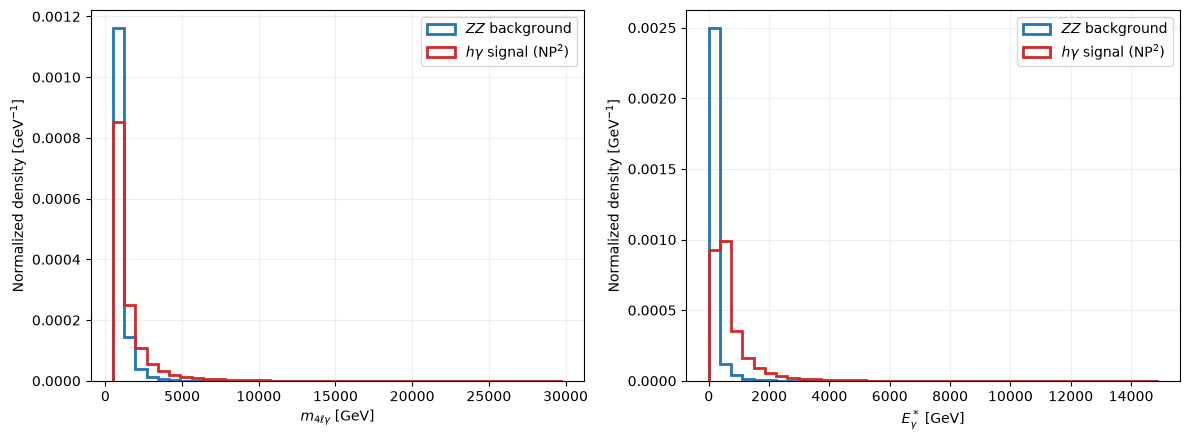

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, variable, xlabel in zip(
    axes,
    ("mass", "energy"),
    (r"$m_{4\ell\gamma}$ [GeV]", r"$E_\gamma^*$ [GeV]"),
):
    values = np.concatenate([signal[variable], background[variable]])
    lower = mass_cut if variable == "mass" else 0.0
    upper = max(values.max() if values.size else lower + 100, lower + 100)
    bins = np.linspace(lower, upper, 41)

    for sample, label, color in (
        (background, r"$ZZ$ background", "tab:blue"),
        (signal, r"$h\gamma$ signal (NP$^2$)", "tab:red"),
    ):
        if len(sample[variable]) == 0 or sample["weights"].sum() == 0:
            continue

        ax.hist(
            sample[variable],
            bins=bins,
            weights=sample["weights"],
            density=True,
            histtype="step",
            linewidth=2,
            label=label,
            color=color,
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"Normalized density [GeV$^{-1}$]")
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Adding $p p \to h \to \ell^+ \ell^- \ell^+ \ell^-$

Higgs background:
Selected MC events: 16870 / 100000
Expected Higgs-background events: 23200.3


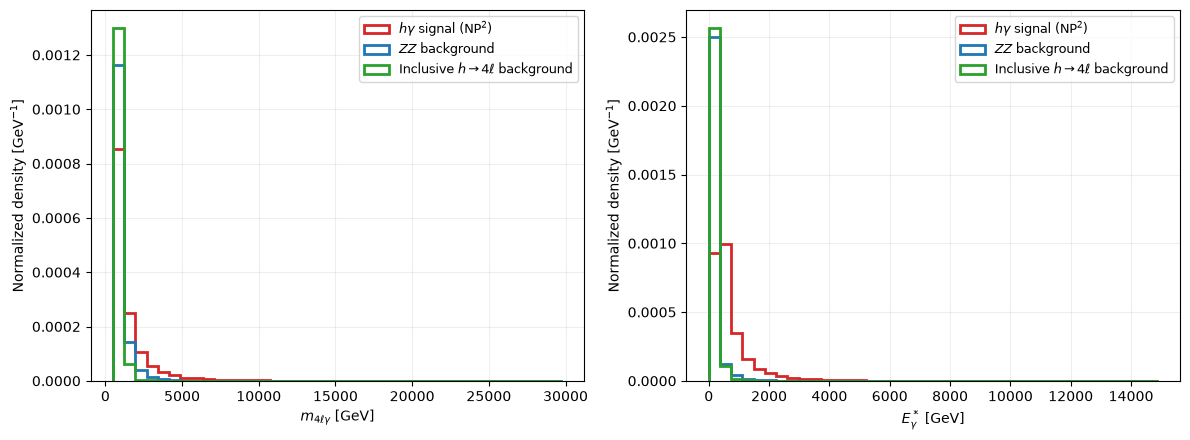

In [ ]:
# ---------- Additional Higgs background ----------

higgs_file = "/Volumes/Keshav_NVMeM2/FCC-hh-runs/pp_to_ha/bckg/gg_h_4l_fresh/Events/run_02/tag_1_delphes_events.root"
sigma_higgs_pb = 0.006524155   # MG cross section including h -> 4l, in pb

if sigma_higgs_pb is None:
    raise ValueError("Enter the Higgs-background cross section in pb.")

print("Higgs background:")
higgs_background = read_sample(higgs_file, sigma_higgs_pb)

print(
    "Expected Higgs-background events:",
    f"{higgs_background['weights'].sum():.6g}"
)


# ---------- Compare all three shapes ----------

plot_samples = [
    (signal, r"$h\gamma$ signal (NP$^2$)", "tab:red"),
    (background, r"$ZZ$ background", "tab:blue"),
    (higgs_background, r"Inclusive $h\to4\ell$ background", "tab:green"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, variable, xlabel in zip(
    axes,
    ("mass", "energy"),
    (r"$m_{4\ell\gamma}$ [GeV]", r"$E_\gamma^*$ [GeV]"),
):
    values = np.concatenate([
        sample[variable] for sample, _, _ in plot_samples
    ])

    lower = mass_cut if variable == "mass" else 0.0
    upper = max(values.max() if values.size else lower + 100, lower + 100)
    bins = np.linspace(lower, upper, 41)

    for sample, label, color in plot_samples:
        if len(sample[variable]) == 0 or sample["weights"].sum() == 0:
            print(f"No selected events to plot: {label}")
            continue

        ax.hist(
            sample[variable],
            bins=bins,
            weights=sample["weights"],
            density=True,
            histtype="step",
            linewidth=2,
            label=label,
            color=color,
        )

    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"Normalized density [GeV$^{-1}$]")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
plot_samples = [
    (signal, r"$h\gamma$ signal (NP$^2$)", "tab:red"),
    (background, r"$ZZ$ background", "tab:blue"),
    (higgs_background, r"Inclusive $h\to4\ell$ background", "tab:green"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

settings = [
    ("mass", np.arange(500, 5000 + 100, 100),
     r"$m_{4\ell\gamma}$ [GeV]"),
    ("energy", np.arange(0, 2500 + 50, 50),
     r"$E_\gamma^*$ [GeV]"),
]

for ax, (variable, bins, xlabel) in zip(axes, settings):
    for sample, label, color in plot_samples:
        weights = sample["weights"]
        if len(weights) == 0 or weights.sum() == 0:
            continue

        counts, _ = np.histogram(
            sample[variable], bins=bins, weights=weights
        )

        # Normalize to the full selected sample, including the hidden tail.
        density = counts / (weights.sum() * np.diff(bins))

        ax.stairs(density, bins, label=label, color=color, linewidth=2)

    ax.set_xlim(bins[0], bins[-1])
    ax.set_xlabel(xlabel)
    ax.set_ylabel(r"Normalized density [GeV$^{-1}$]")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

NameError: name 'signal' is not defined